# TP3 — Redes Bayesianas

**UFMG · Engenharia de Sistemas · EEE048 Fundamentos de Inteligência Artificial**

Cecília Rodrigues Saraiva · Caio César Araújo Guimarães · Stéphanie Pereira Barbosa · Thales Eduardo Dias de Souza

Este notebook usa a implementação de `tp3.py` e `analises.py`. Execute as células em ordem, na pasta extraída do projeto. A base está incluída; sua aprovação prévia pelos professores precisa ser confirmada pelo grupo. Os arquivos produzidos estão descritos em `ARQUIVOS_GERADOS.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import tp3

BASE = Path(tp3.__file__).resolve().parent
print('Pasta do projeto:', BASE)
print('Variáveis:', tp3.COLUNAS)

Pasta do projeto: /workspace/scratch/f8928f144a81/TP3_Codigo
Variáveis: ['age', 'Medu', 'studytime', 'failures', 'schoolsup', 'higher', 'absences', 'G1', 'G2', 'G3']


/workspace/scratch/f8928f144a81/tmp/venv_tp3_313/lib/python3.13/site-packages/pgmpy/factors/base.py:81: SyntaxWarning: invalid escape sequence '\s'
  For a given set of factors: `args` returns the result of $ \sum_{var \not \in output_vars} \prod \textit{args} $.
/workspace/scratch/f8928f144a81/tmp/venv_tp3_313/lib/python3.13/site-packages/pgmpy/extern/tabulate.py:151: SyntaxWarning: invalid escape sequence '\h'
  return "\\begin{tabular}{" + tabular_columns_fmt + "}\n\hline"
/workspace/scratch/f8928f144a81/tmp/venv_tp3_313/lib/python3.13/site-packages/pgmpy/extern/tabulate.py:256: SyntaxWarning: invalid escape sequence '\['
  _invisible_codes = re.compile("\x1b\[\d*m")  # ANSI color codes
/workspace/scratch/f8928f144a81/tmp/venv_tp3_313/lib/python3.13/site-packages/pgmpy/extern/tabulate.py:257: SyntaxWarning: invalid escape sequence '\['
  _invisible_codes_bytes = re.compile(b"\x1b\[\d*m")  # ANSI color codes
/workspace/scratch/f8928f144a81/tmp/venv_tp3_313/lib/python3.13/site-package

## Tarefas 1 e 2 — Dados e hipótese inicial
Os limites são calculados somente no treino. As categorias naturais são preservadas; a hipótese de grafo fica definida antes do aprendizado.

In [2]:
treino, teste, resumo = tp3.preparar_dados()
display(pd.DataFrame(resumo['cortes'], index=['mínimo', 'quantil 1/3', 'quantil 2/3', 'máximo']).T)
display(pd.DataFrame(tp3.ARESTAS_MANUAIS, columns=['origem', 'destino']))
print('Treino:', len(treino), '| Teste:', len(teste))

Treino: 519 | Teste: 130


,mínimo,quantil 1/3,quantil 2/3,máximo
age,15.0,16.0,17.0,22.0
absences,0.0,0.0,4.0,32.0
G1,0.0,10.0,12.0,18.0
G2,0.0,10.0,13.0,19.0
G3,0.0,11.0,13.0,19.0


,origem,destino
0,Medu,higher
1,higher,studytime
2,studytime,G1
3,failures,G1
4,schoolsup,G1
5,absences,G3
6,G1,G2
7,G2,G3
8,age,failures


## Tarefas 3, 4 e 5 — Execução completa
Aprende as estruturas, ajusta CPTs com BDeu, faz as inferências e exporta as figuras e tabelas. A pasta `resultados/` é atualizada.

In [3]:
resultado = tp3.executar()

       metodo   bic_treino  arestas  parametros_livres
Hill-Climbing -4118.115182        8                 46
     Chow-Liu -4127.248544        9                 54

Modelo escolhido: Hill-Climbing
                          cenario  n_treino_evidencia    baixa    media     alta
                    Sem evidência                 519 0.468830 0.241730 0.289440
                         G2 baixa                 192 0.978772 0.013196 0.008032
                          G2 alta                 116 0.004721 0.030217 0.965061
           G2 baixa e reprovações                  69 0.978772 0.013196 0.008032
Deseja graduação e estuda 5 a 10h                  70 0.197199 0.314615 0.488186
                     Faltas altas                 146 0.468830 0.241730 0.289440

Avaliação: [{'metodo': 'Hill-Climbing', 'acuracia': 0.7769230769230769, 'log_loss': 0.49168947151565656}, {'metodo': 'Chow-Liu', 'acuracia': 0.7769230769230769, 'log_loss': 0.4916894715156565}] 
Baseline: {'acuracia': 0.43846153846153

## Comparação estrutural
Maior BIC é melhor nesta convenção. A direção das setas aprendidas não comprova causalidade.

In [4]:
display(pd.DataFrame(resultado['comparacao']))
resultado['comparacao_manual']

Out[4]: 
{'Hill-Climbing': {'mesma_direcao': [],
  'invertidas': [('G1', 'G2'),
   ('G2', 'G3'),
   ('age', 'failures'),
   ('failures', 'G1')],
  'ausentes': [('G1', 'schoolsup'),
   ('G1', 'studytime'),
   ('G3', 'absences'),
   ('Medu', 'higher'),
   ('higher', 'studytime')],
  'novas': [('G1', 'higher'),
   ('G3', 'schoolsup'),
   ('G3', 'studytime'),
   ('Medu', 'failures')],
  'jaccard_esqueleto': 0.3076923076923077},
 'Chow-Liu': {'mesma_direcao': [],
  'invertidas': [('G1', 'G2'),
   ('G2', 'G3'),
   ('age', 'failures'),
   ('failures', 'G1')],
  'ausentes': [('G1', 'schoolsup'),
   ('G1', 'studytime'),
   ('G3', 'absences'),
   ('Medu', 'higher'),
   ('higher', 'studytime')],
  'novas': [('G1', 'higher'),
   ('G2', 'Medu'),
   ('G3', 'schoolsup'),
   ('G3', 'studytime'),
   ('absences', 'age')],
  'jaccard_esqueleto': 0.2857142857142857}}


,metodo,bic_treino,arestas,parametros_livres
0,Hill-Climbing,-4118.115182,8,46
1,Chow-Liu,-4127.248544,9,54


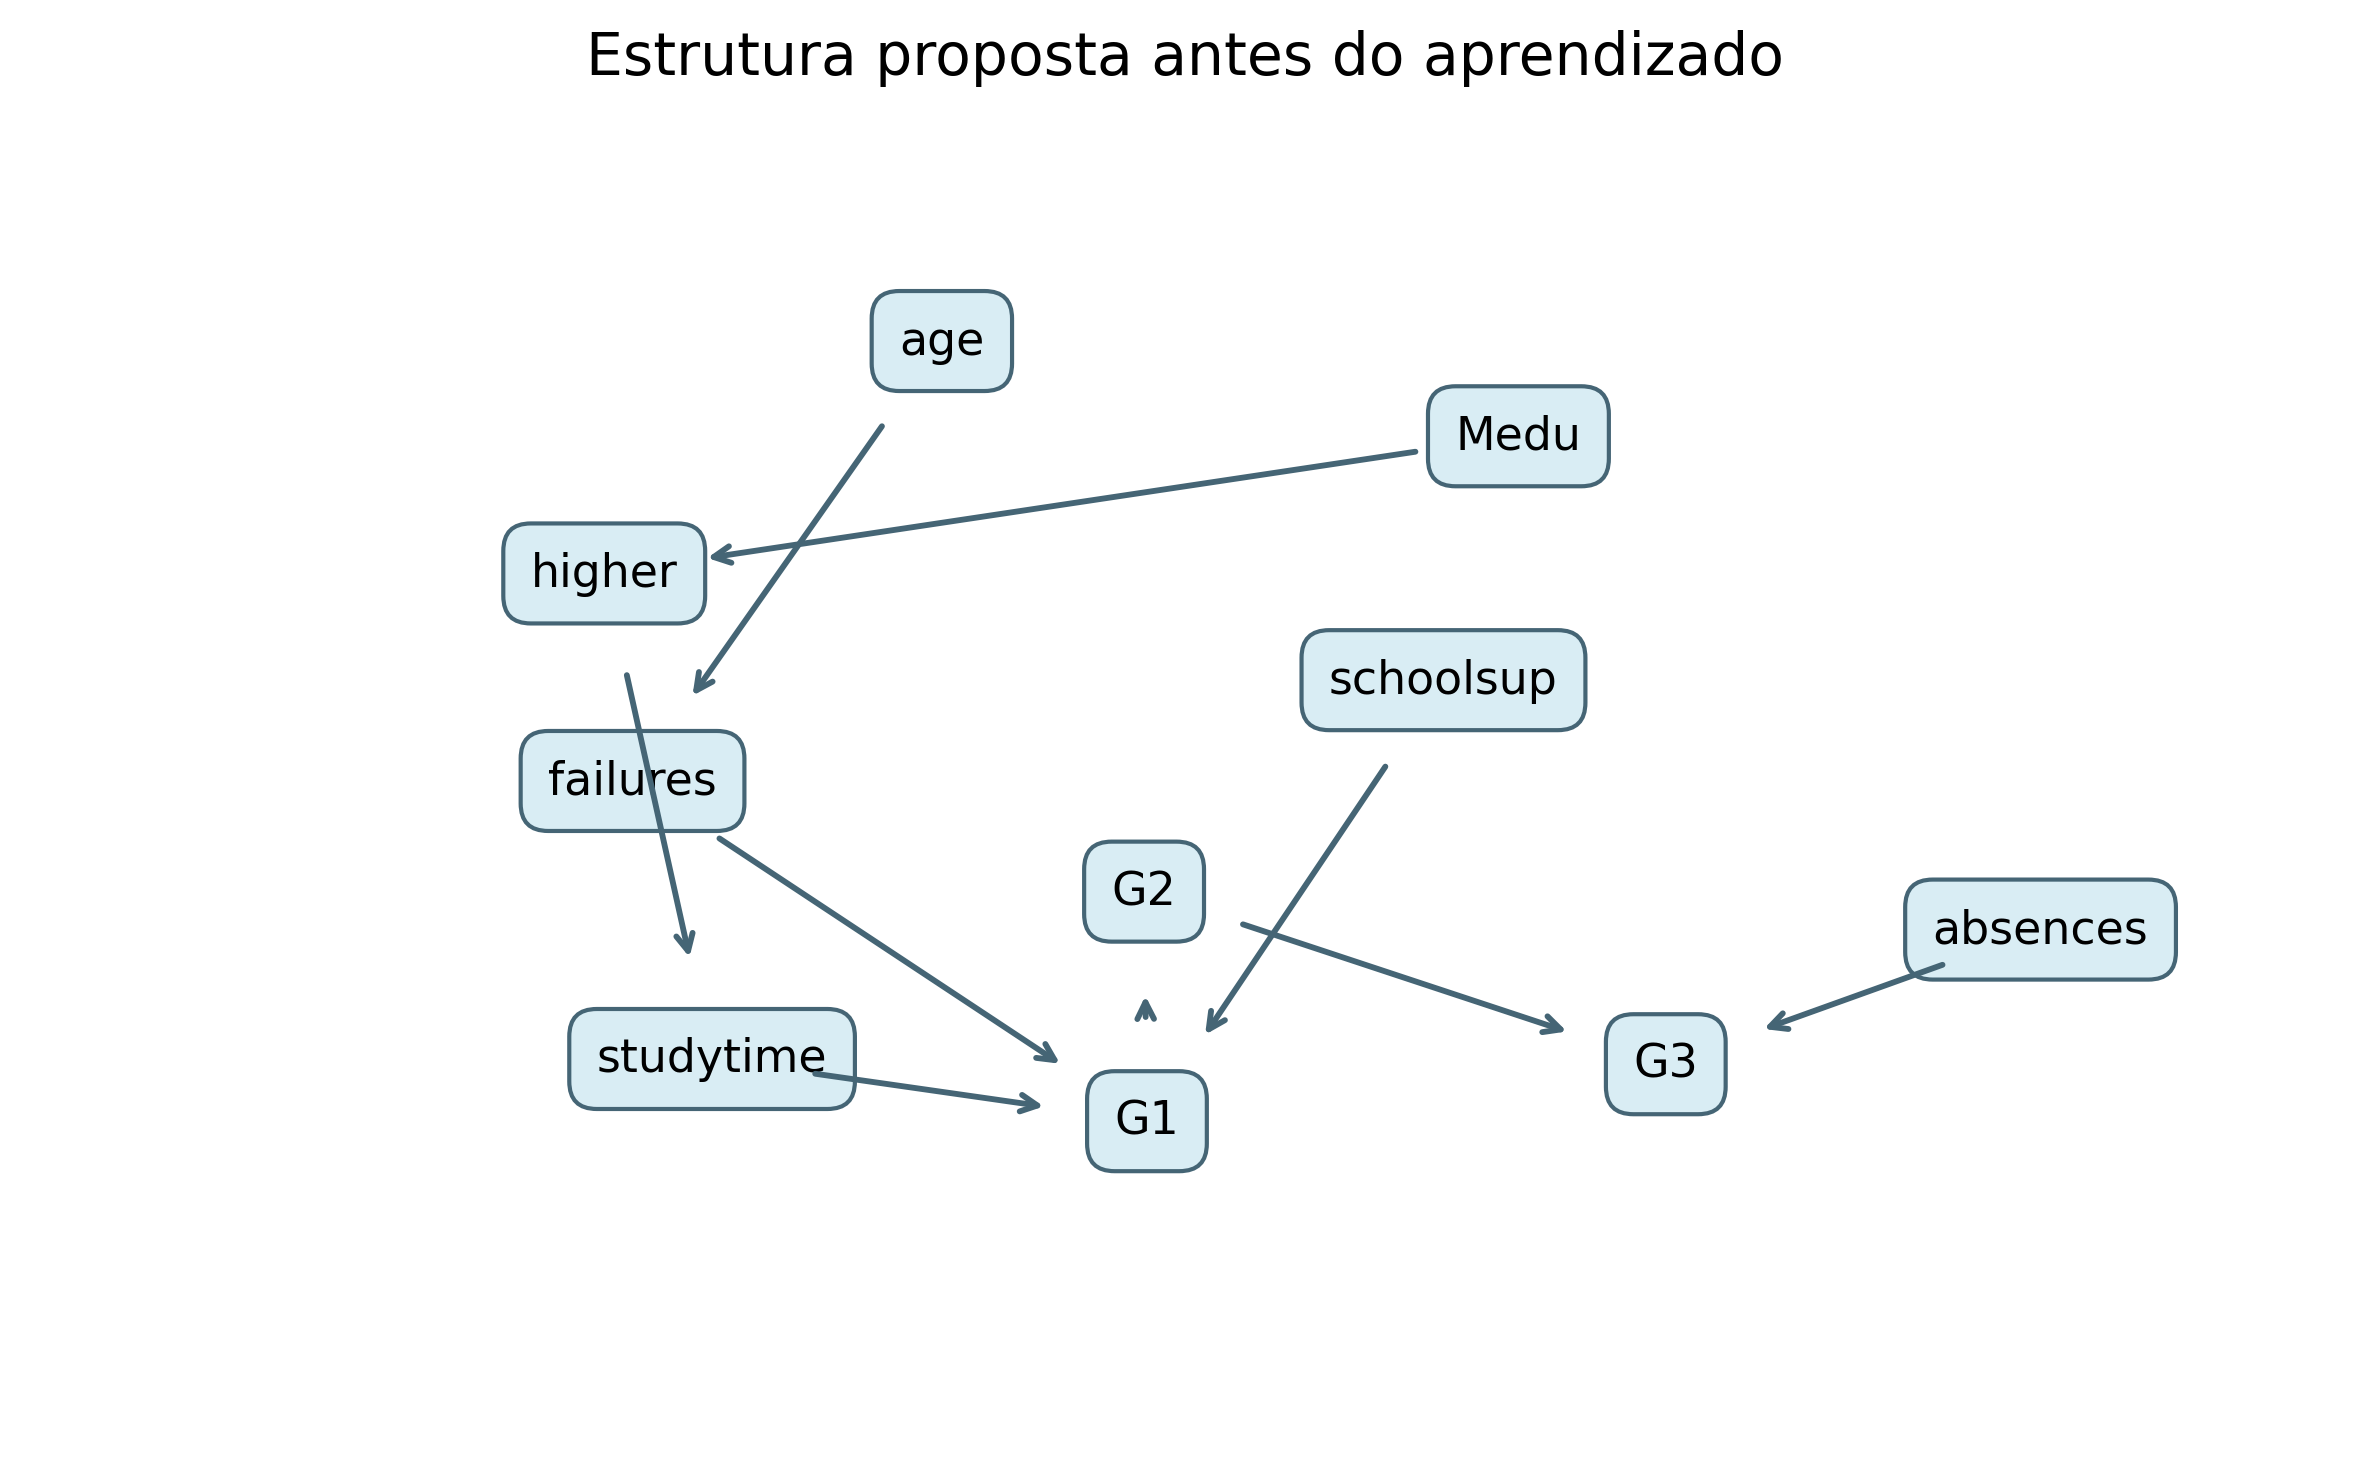

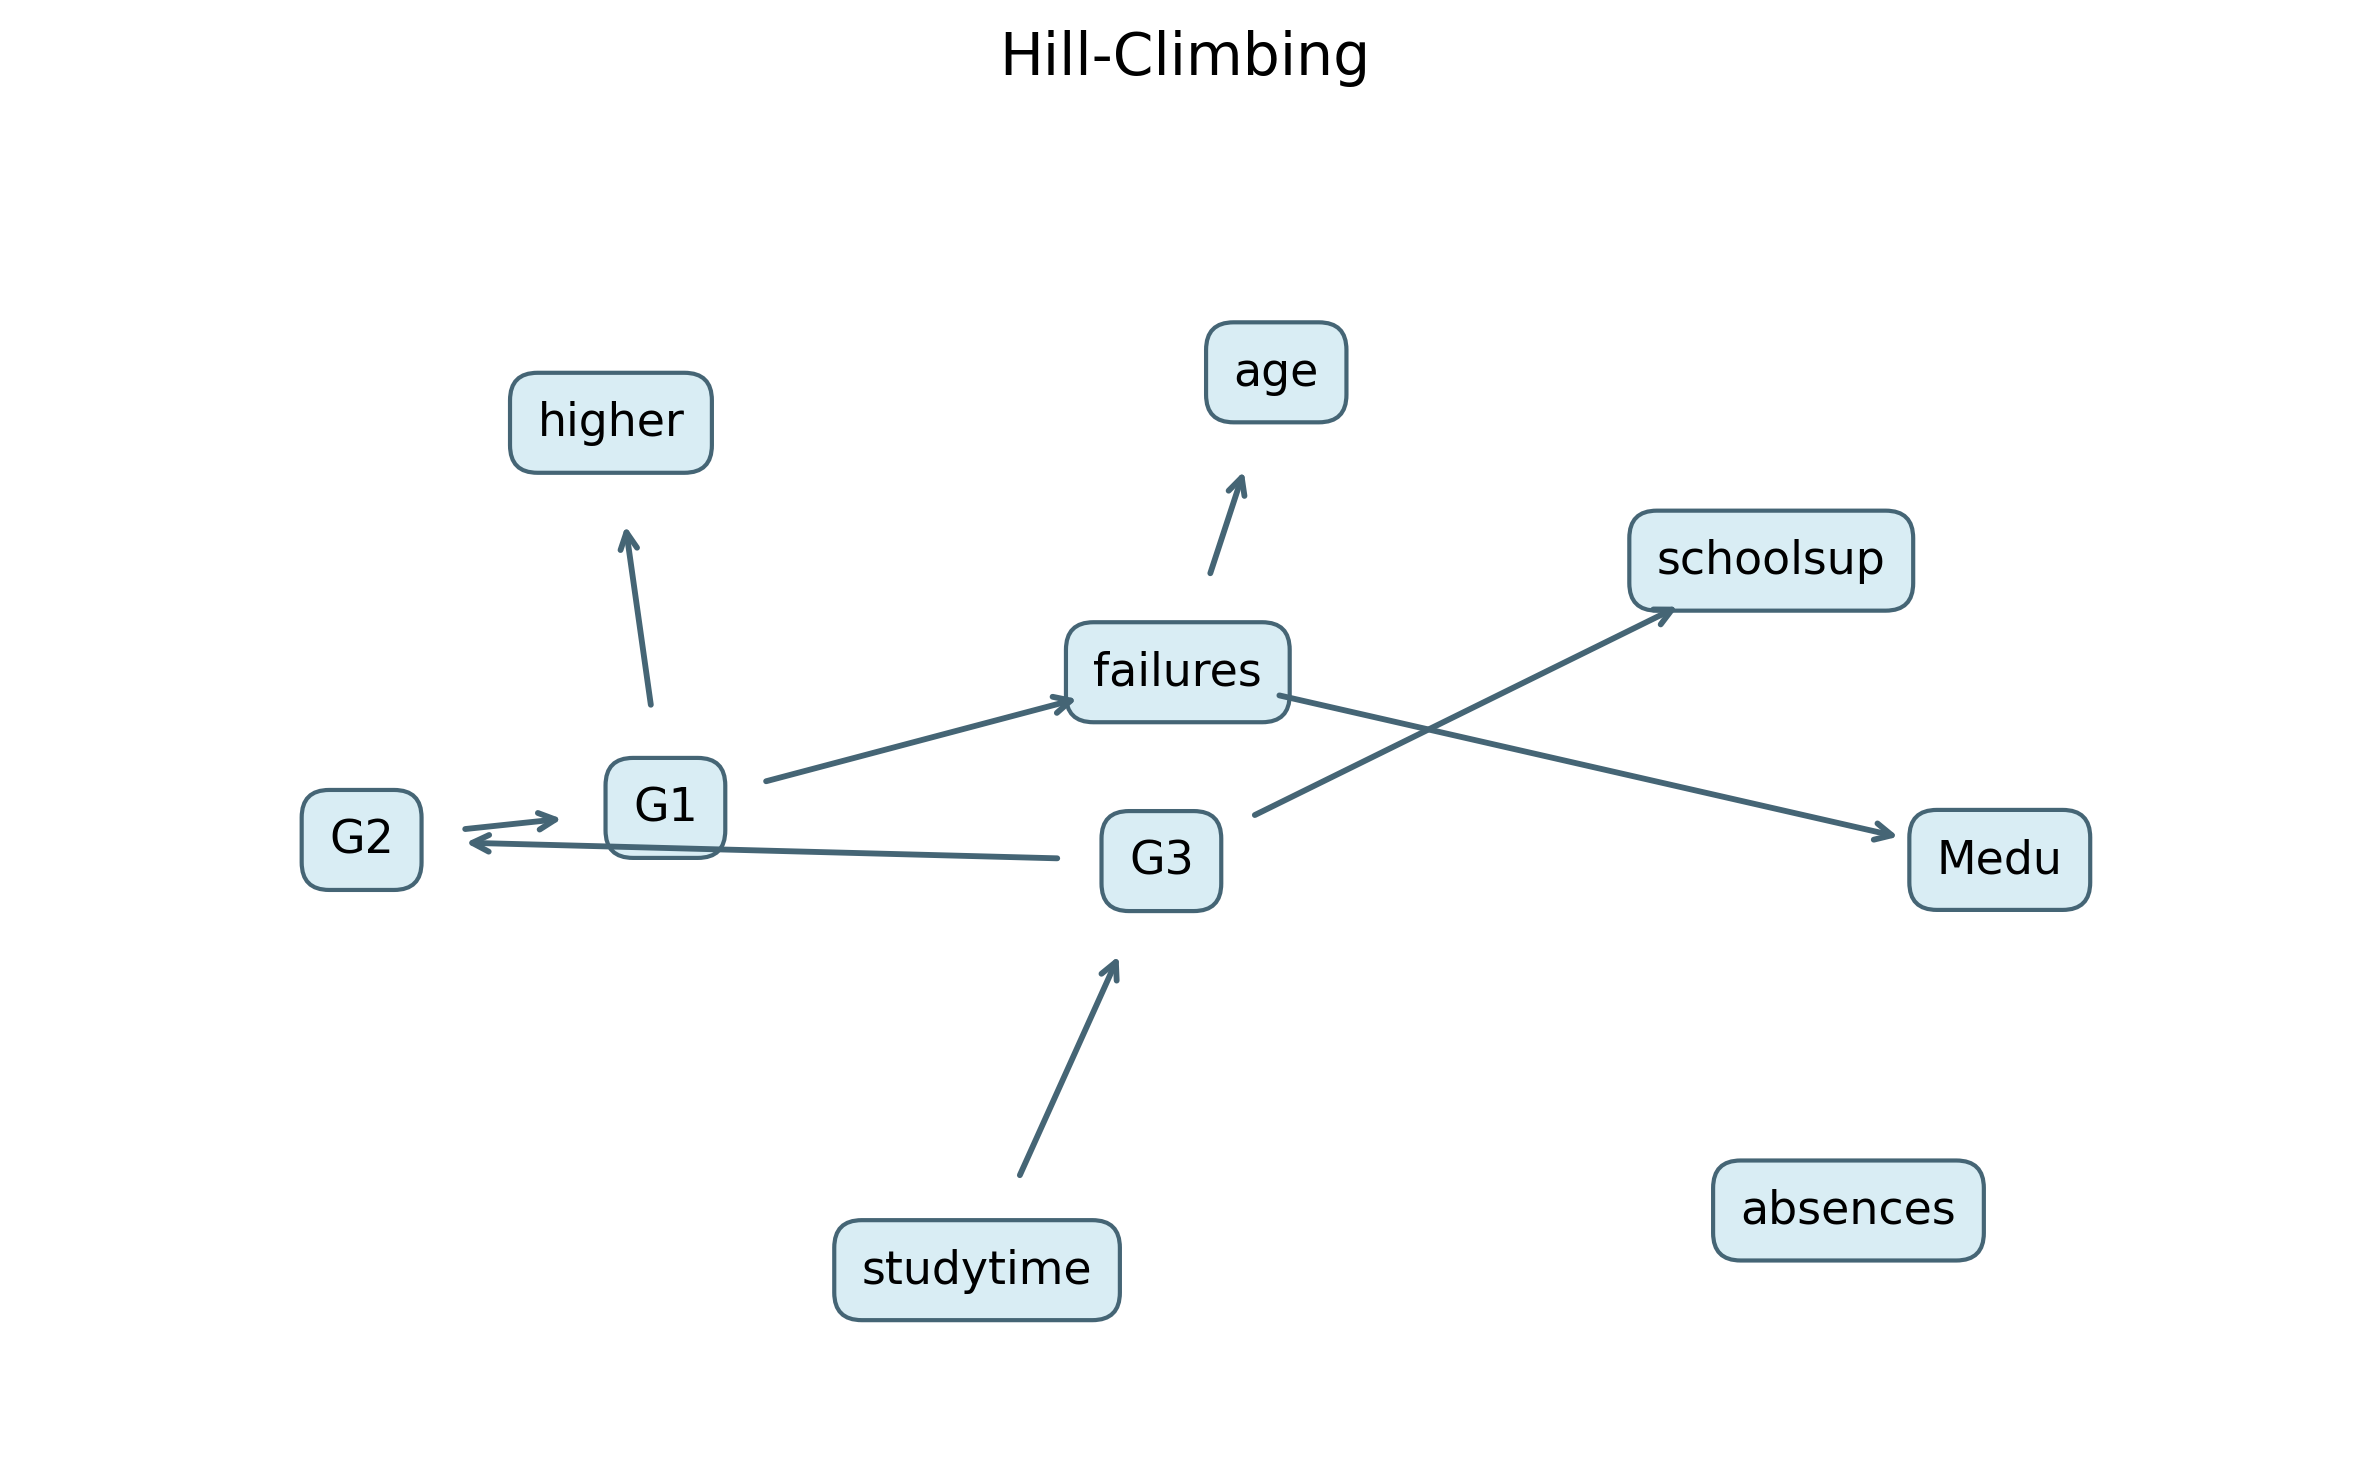

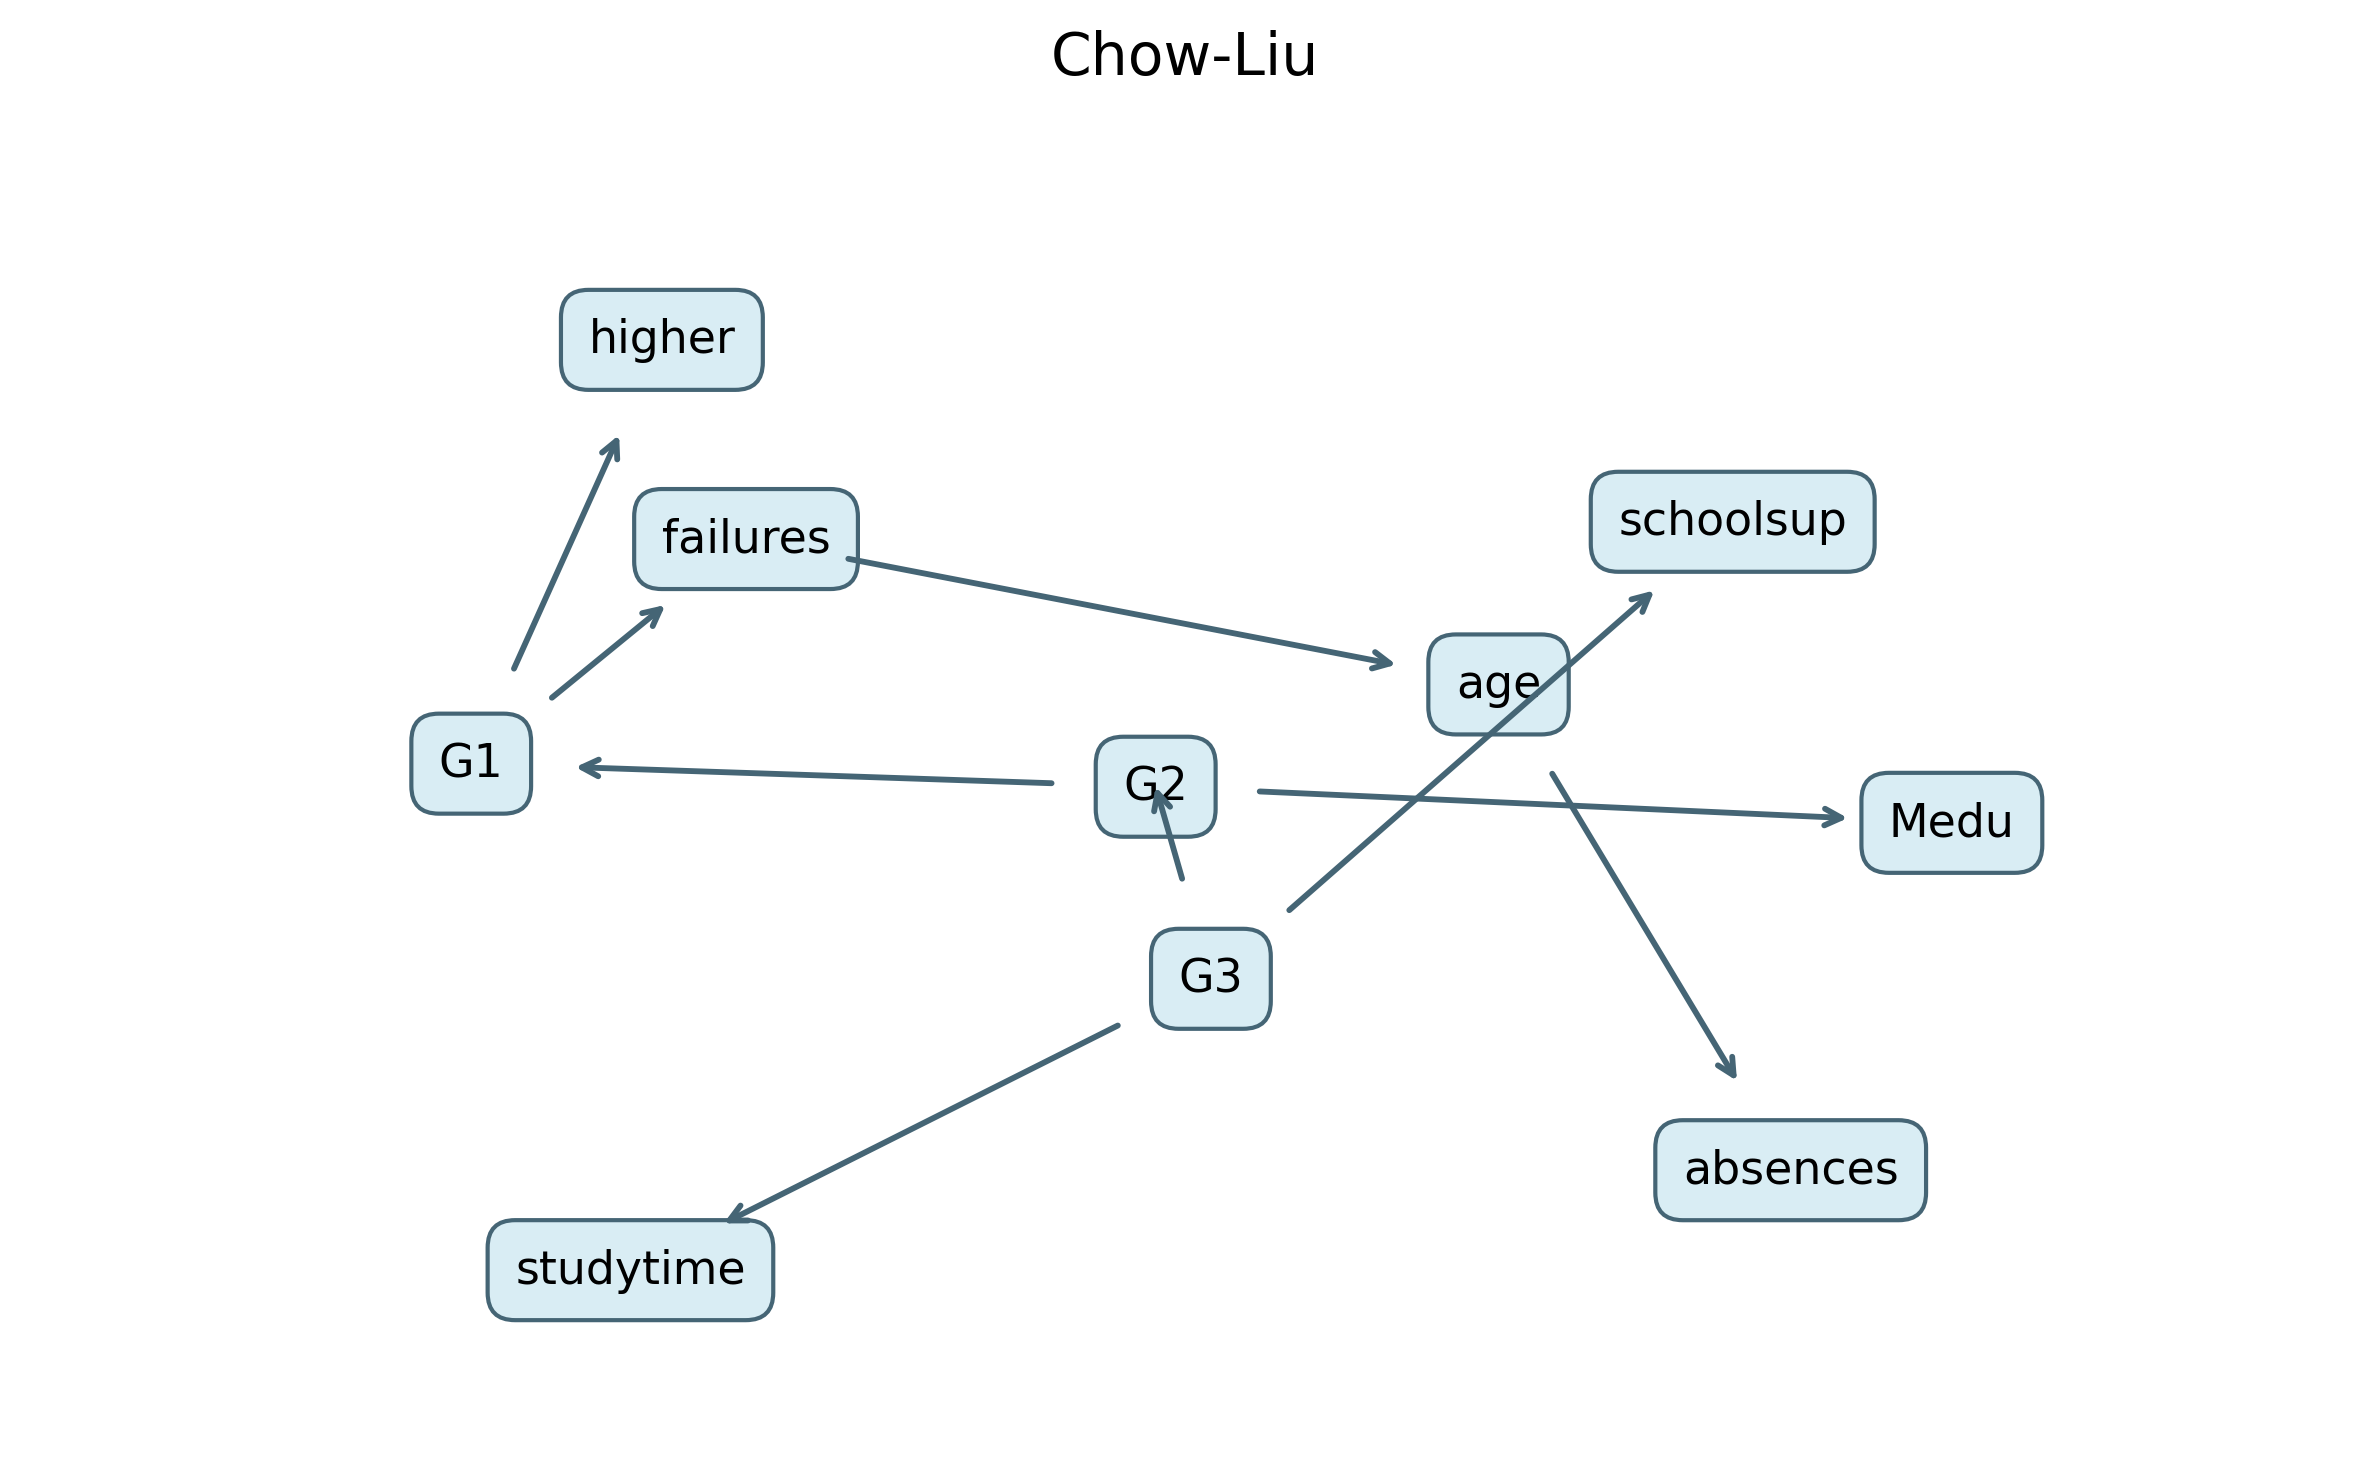

In [5]:
for arquivo in ['rede_manual.png', 'rede_hc.png', 'rede_chow_liu.png']:
    display(Image(filename=str(BASE / 'resultados' / arquivo)))

## Inferências com evidência parcial
O suporte informa quantos registros do treino atendem à evidência. A ausência de mudança em uma consulta pode ser explicada pela topologia da rede.

,cenario,evidencia,n_treino_evidencia,baixa,media,alta
0,Sem evidência,{},519,0.468830,0.241730,0.289440
1,G2 baixa,{'G2': 'baixa'},192,0.978772,0.013196,0.008032
2,G2 alta,{'G2': 'alta'},116,0.004721,0.030217,0.965061
3,G2 baixa e reprovações,"{'G2': 'baixa', 'failures': 'uma_ou_mais'}",69,0.978772,0.013196,0.008032
4,Deseja graduação e estuda 5 a 10h,"{'higher': 'yes', 'studytime': '3'}",70,0.197199,0.314615,0.488186
5,Faltas altas,{'absences': 'alta'},146,0.468830,0.241730,0.289440


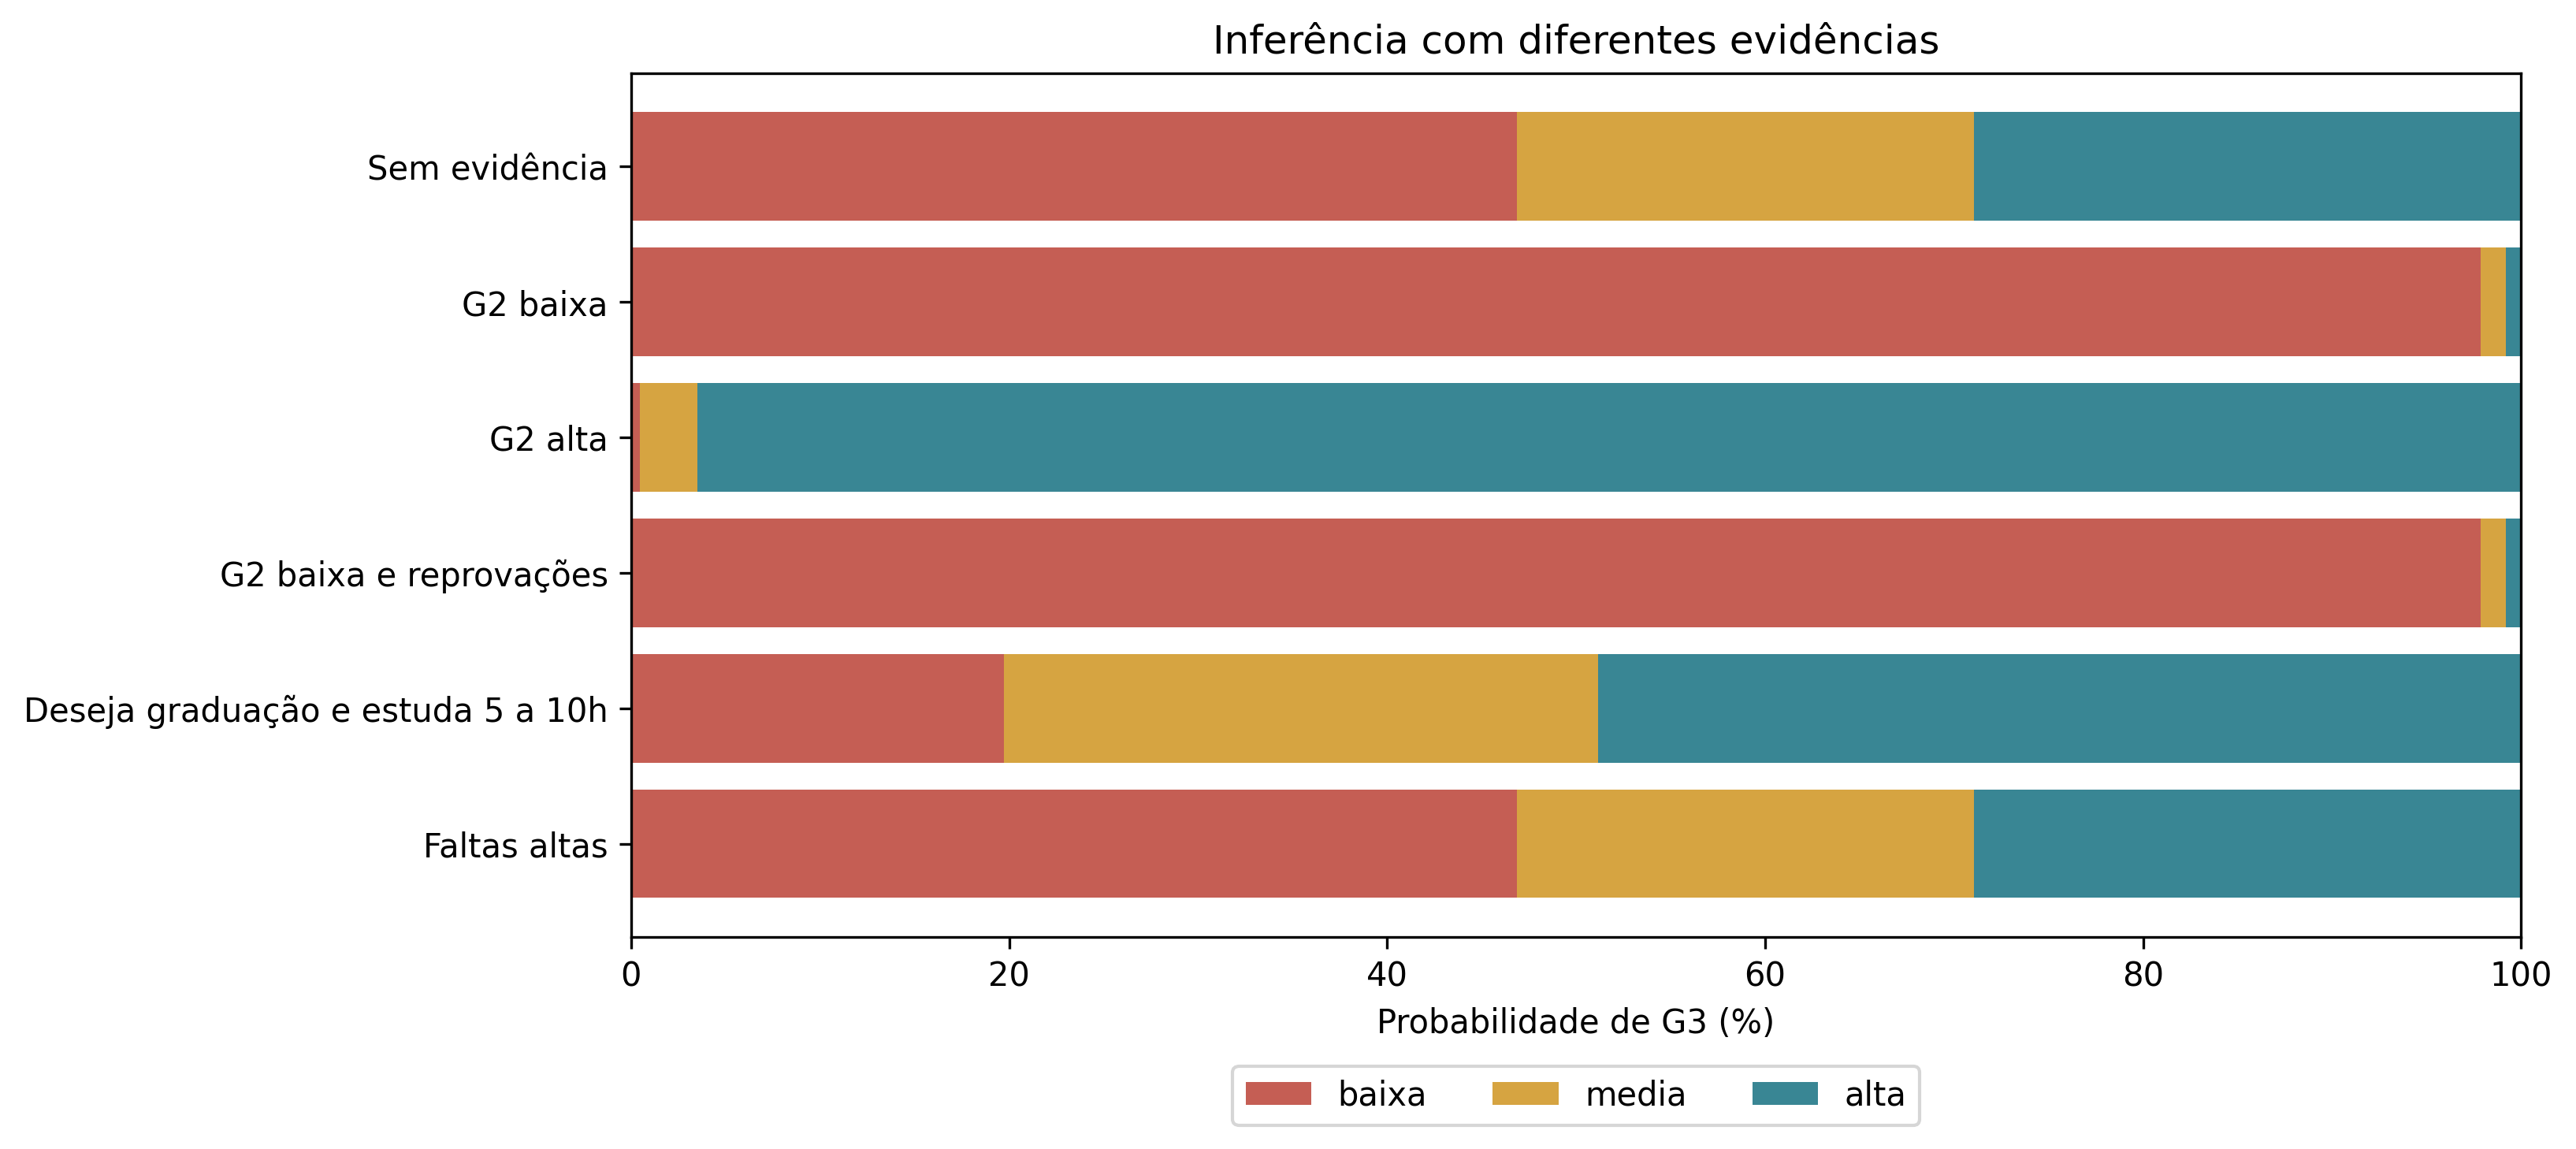

In [6]:
display(pd.DataFrame(resultado['consultas']))
display(Image(filename=str(BASE / 'resultados/figuras/consultas_g3.png')))

## Avaliação em teste
As predições por registro estão em CSV para conferência. O teste não foi usado para escolher a estrutura.

,metodo,acuracia,log_loss
0,Hill-Climbing,0.776923,0.491689
1,Chow-Liu,0.776923,0.491689
2,Baseline marginal,0.438462,1.068614


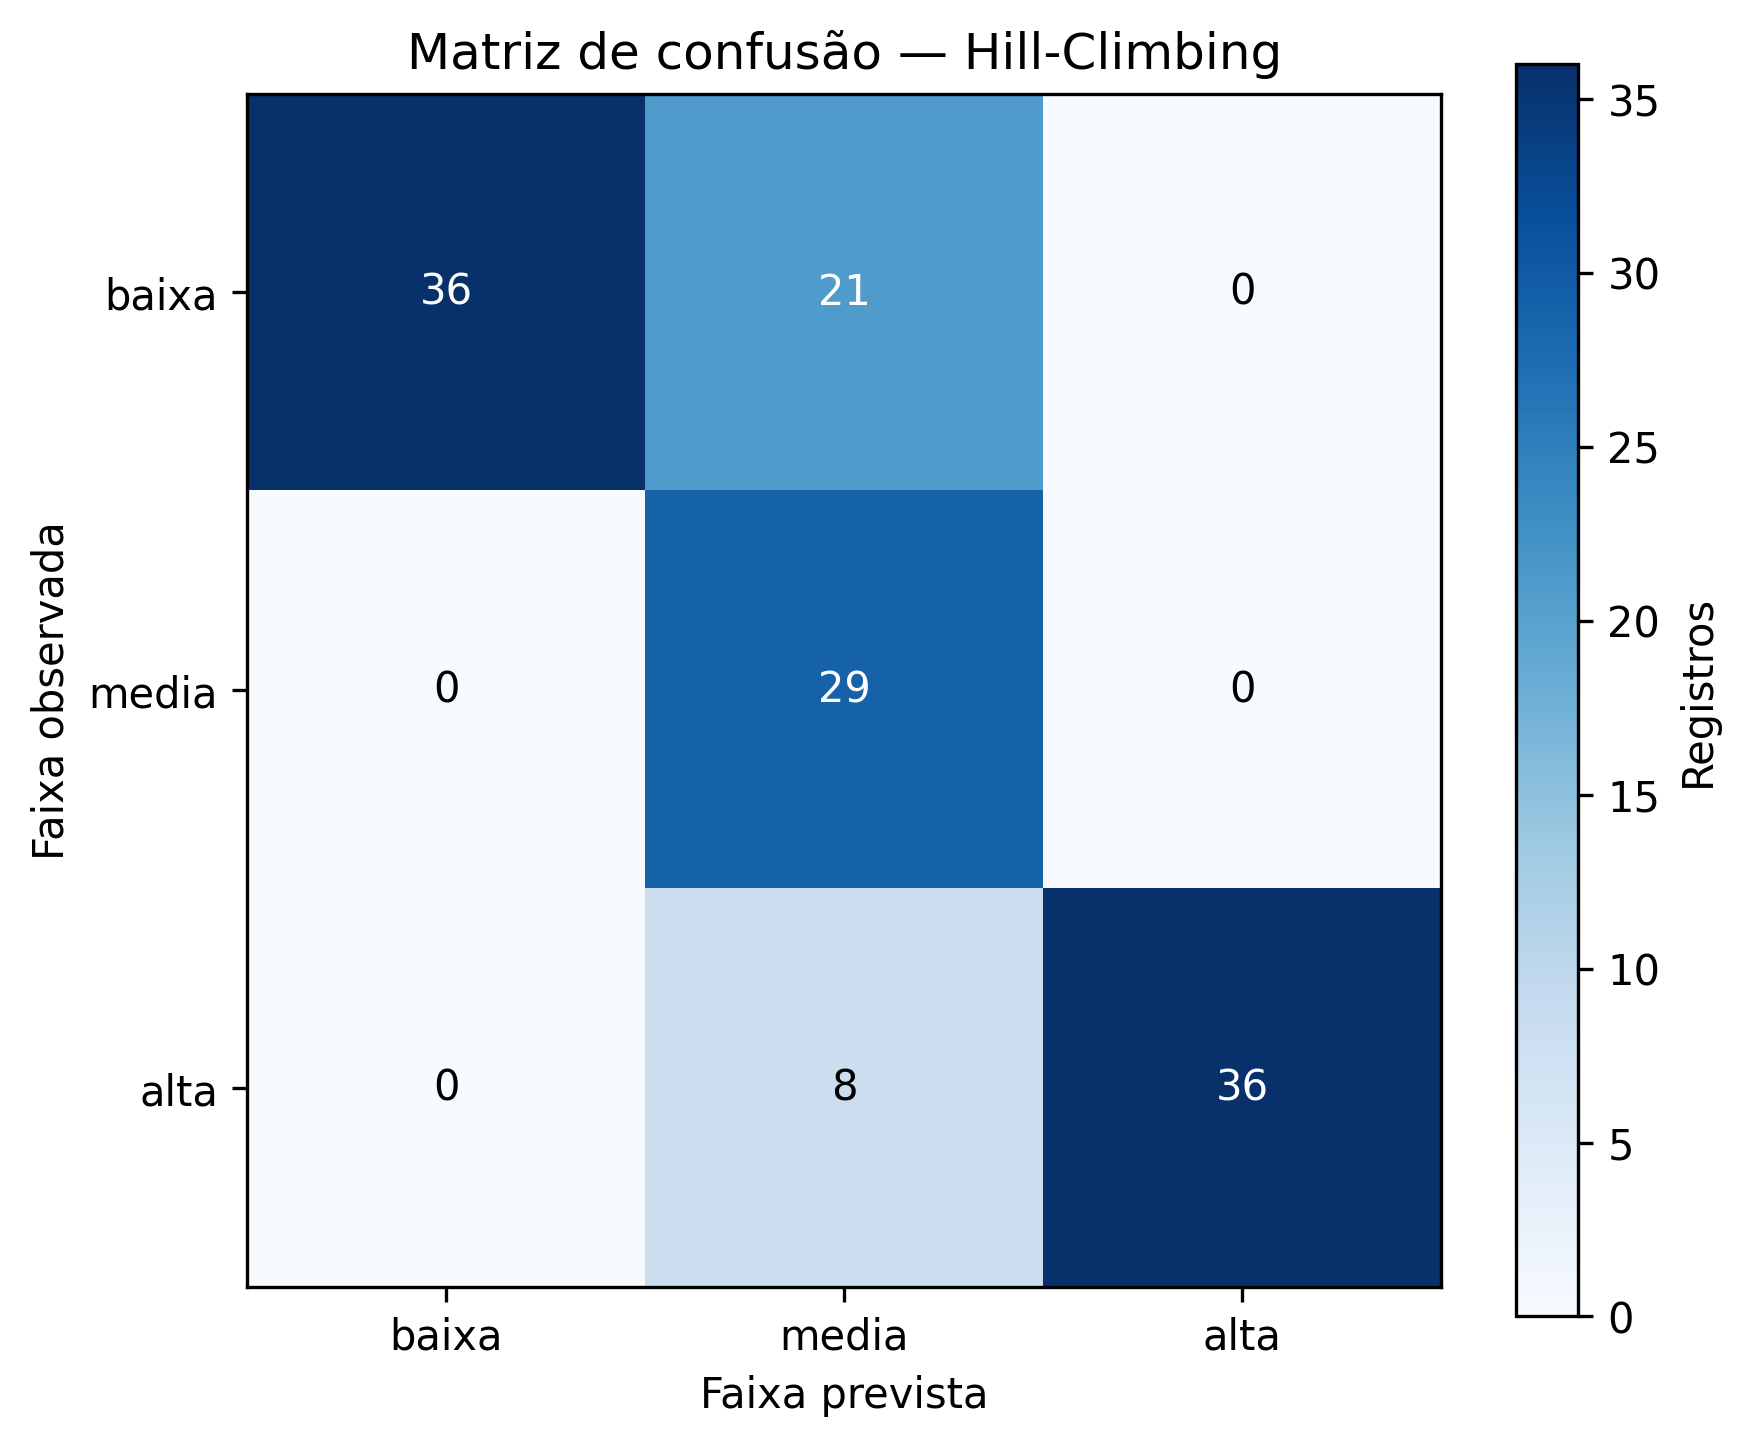

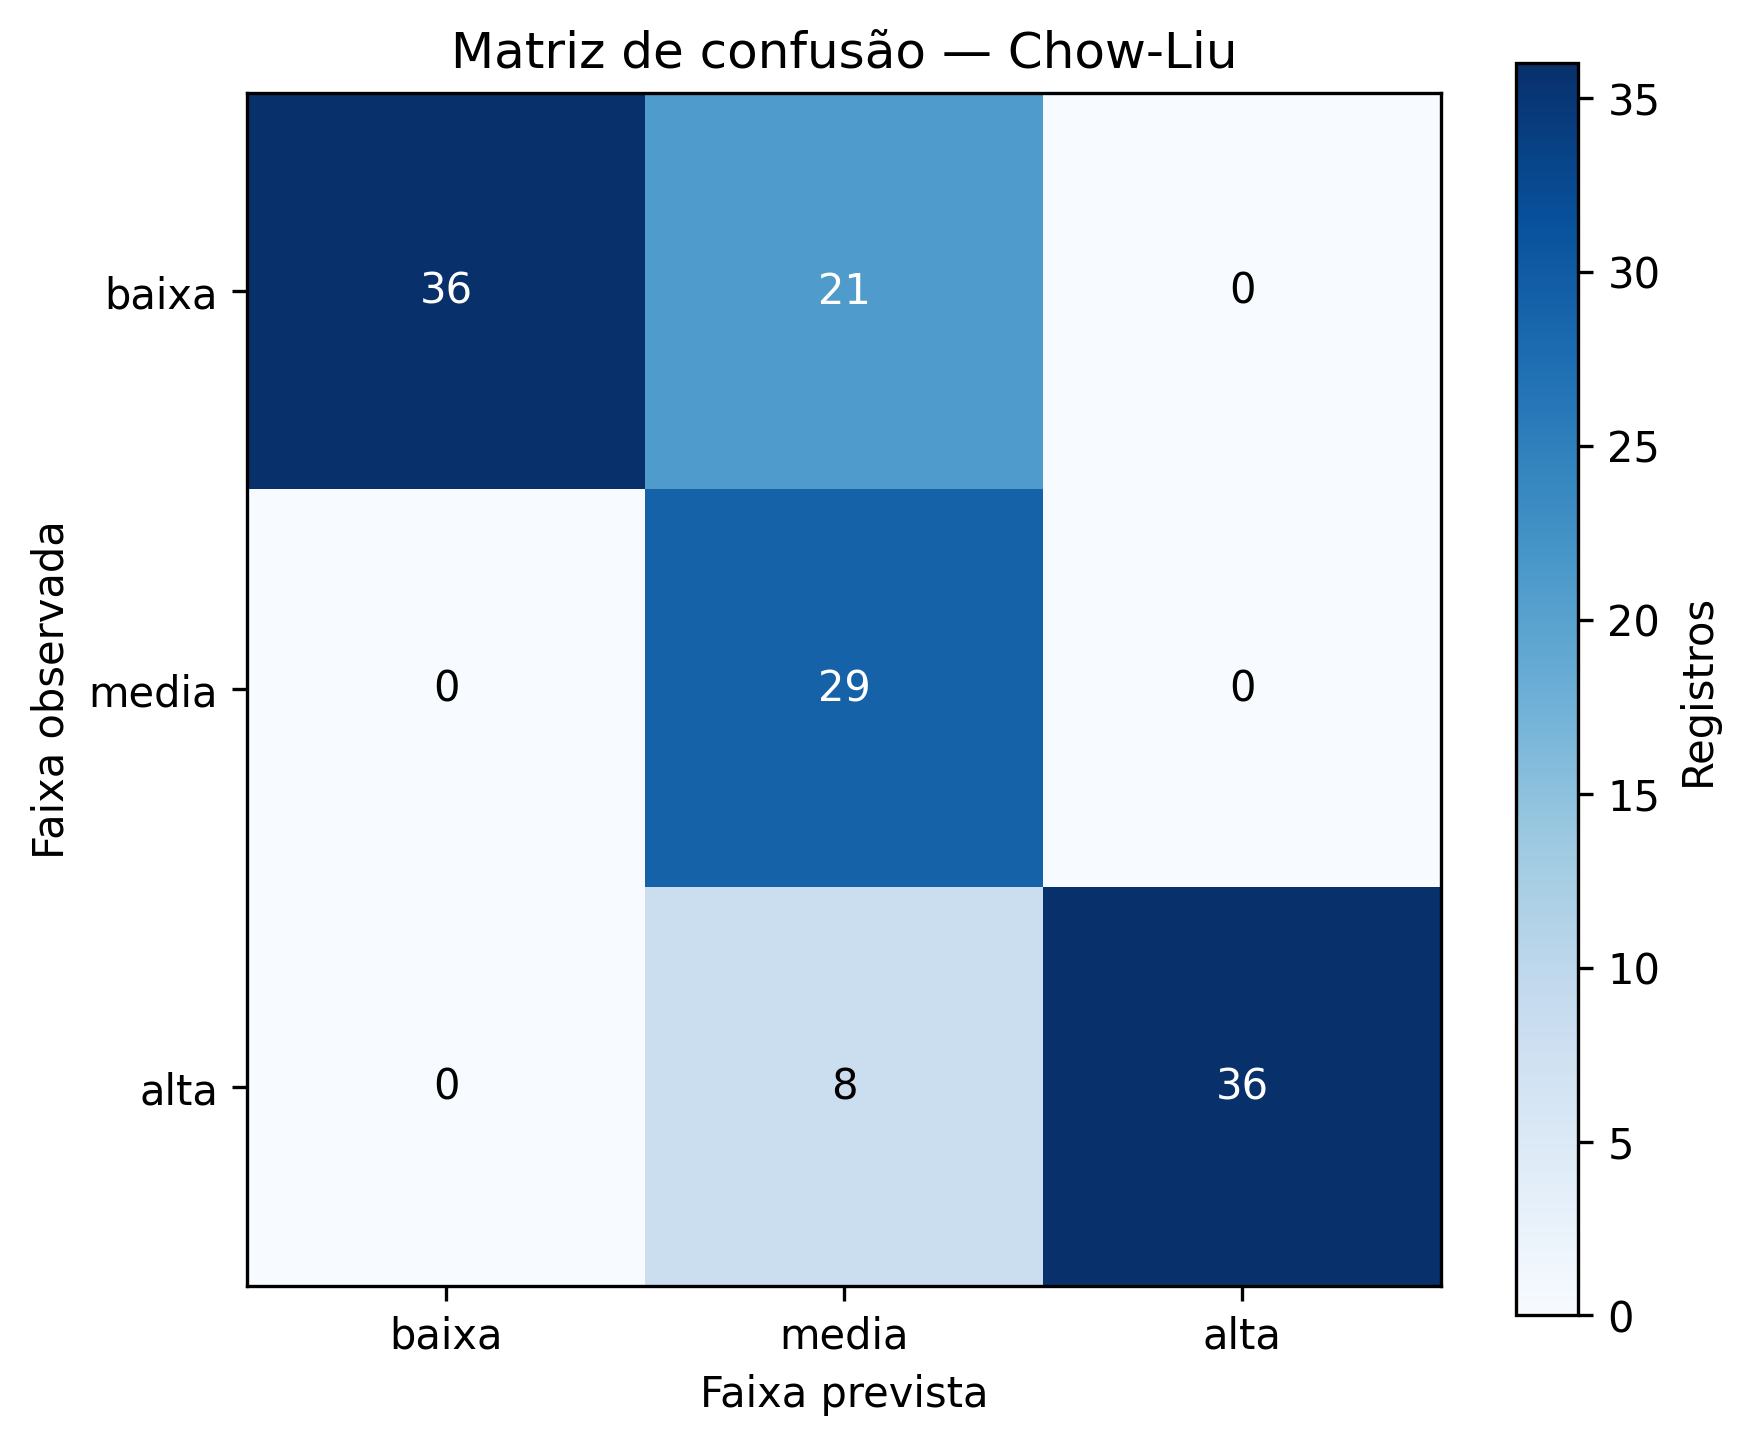

In [7]:
display(pd.read_csv(BASE / 'resultados/tabelas/metricas_teste.csv'))
for chave in ['hc', 'chow_liu']:
    display(Image(filename=str(BASE / f'resultados/figuras/matriz_confusao_{chave}.png')))

## Explicação de um caso
Foi escolhido o primeiro registro do teste por índice original com G2 baixa. A sensibilidade retira uma evidência por vez; os efeitos não são aditivos nem representam importância global.

In [8]:
display(pd.read_csv(BASE / 'resultados/tabelas/caso_explicado.csv'))
display(pd.DataFrame(resultado['caso']['sensibilidade']))
print('Cobertor:', resultado['caso']['markov_blanket'])

Cobertor: ['G2', 'schoolsup', 'studytime']


,indice_original,age,Medu,studytime,failures,schoolsup,higher,absences,G1,G2,G3_real,p_baixa,p_media,p_alta
0,78,media,2,1,uma_ou_mais,yes,no,baixa,baixa,baixa,baixa,0.989362,0.009655,0.000983


,variavel,observado,p_baixa_sem,p_baixa_com,diferenca_pp
0,G2,baixa,0.883722,0.989362,10.564029
1,studytime,1,0.981849,0.989362,0.751258
2,schoolsup,yes,0.988651,0.989362,0.071136
3,age,media,0.989362,0.989362,0.000000
4,Medu,2,0.989362,0.989362,0.000000
5,failures,uma_ou_mais,0.989362,0.989362,0.000000
6,higher,no,0.989362,0.989362,0.000000
7,absences,baixa,0.989362,0.989362,0.000000
8,G1,baixa,0.989362,0.989362,0.000000


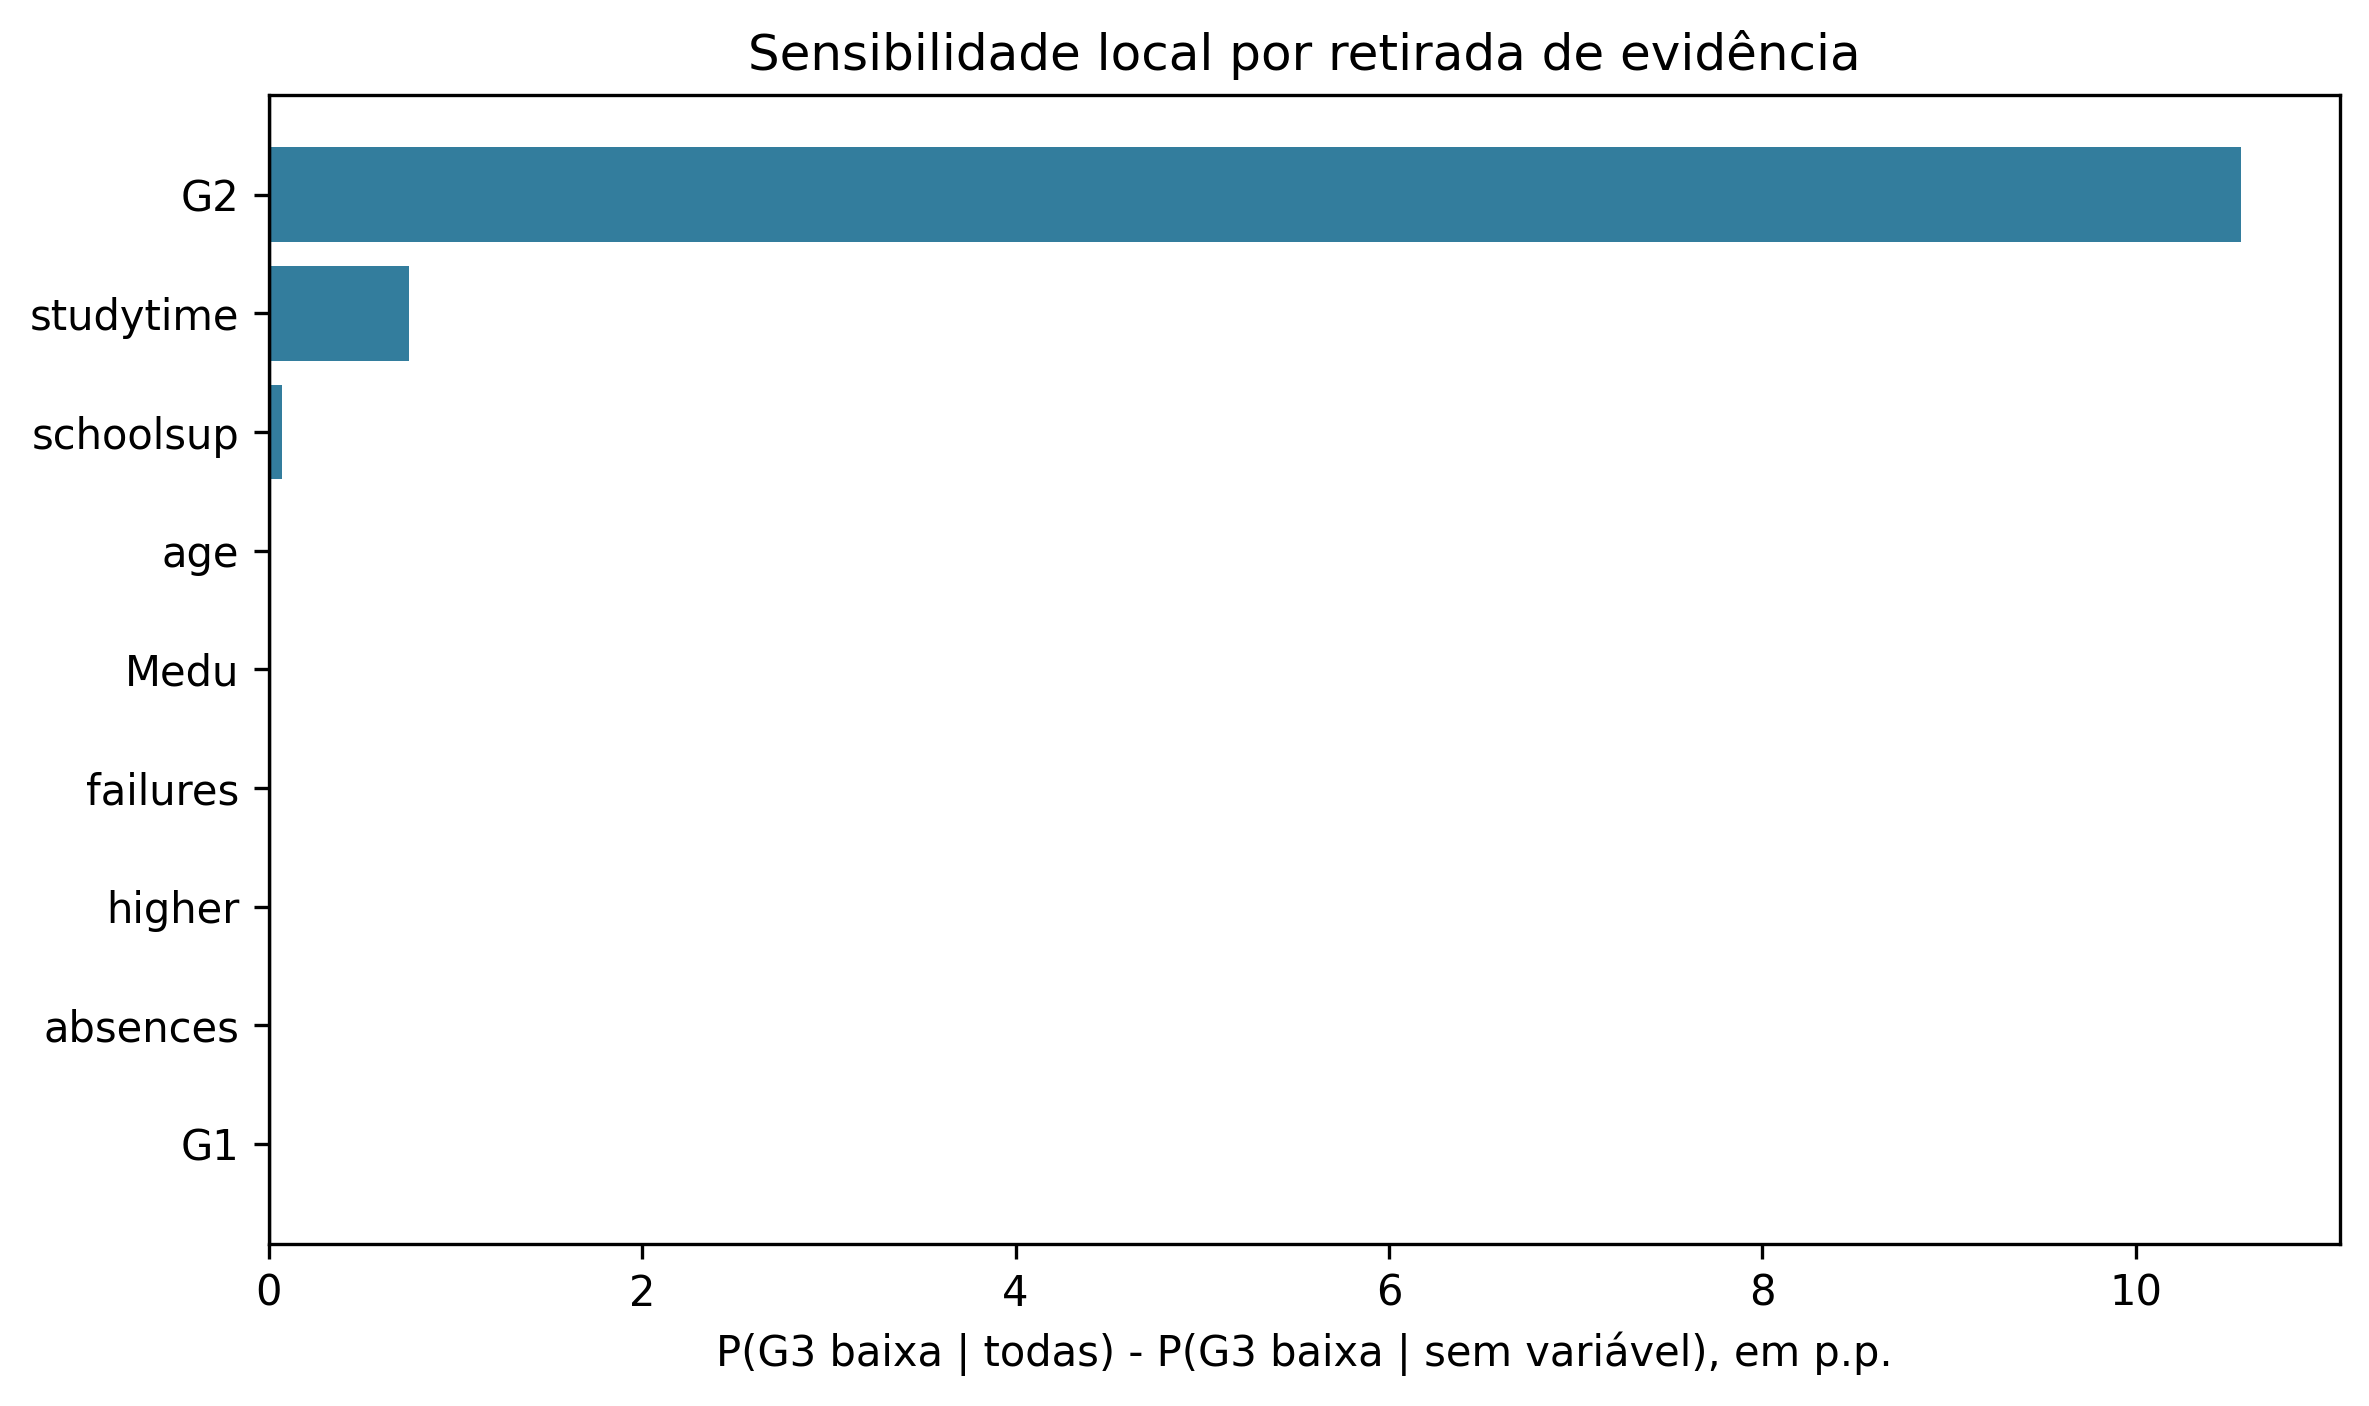

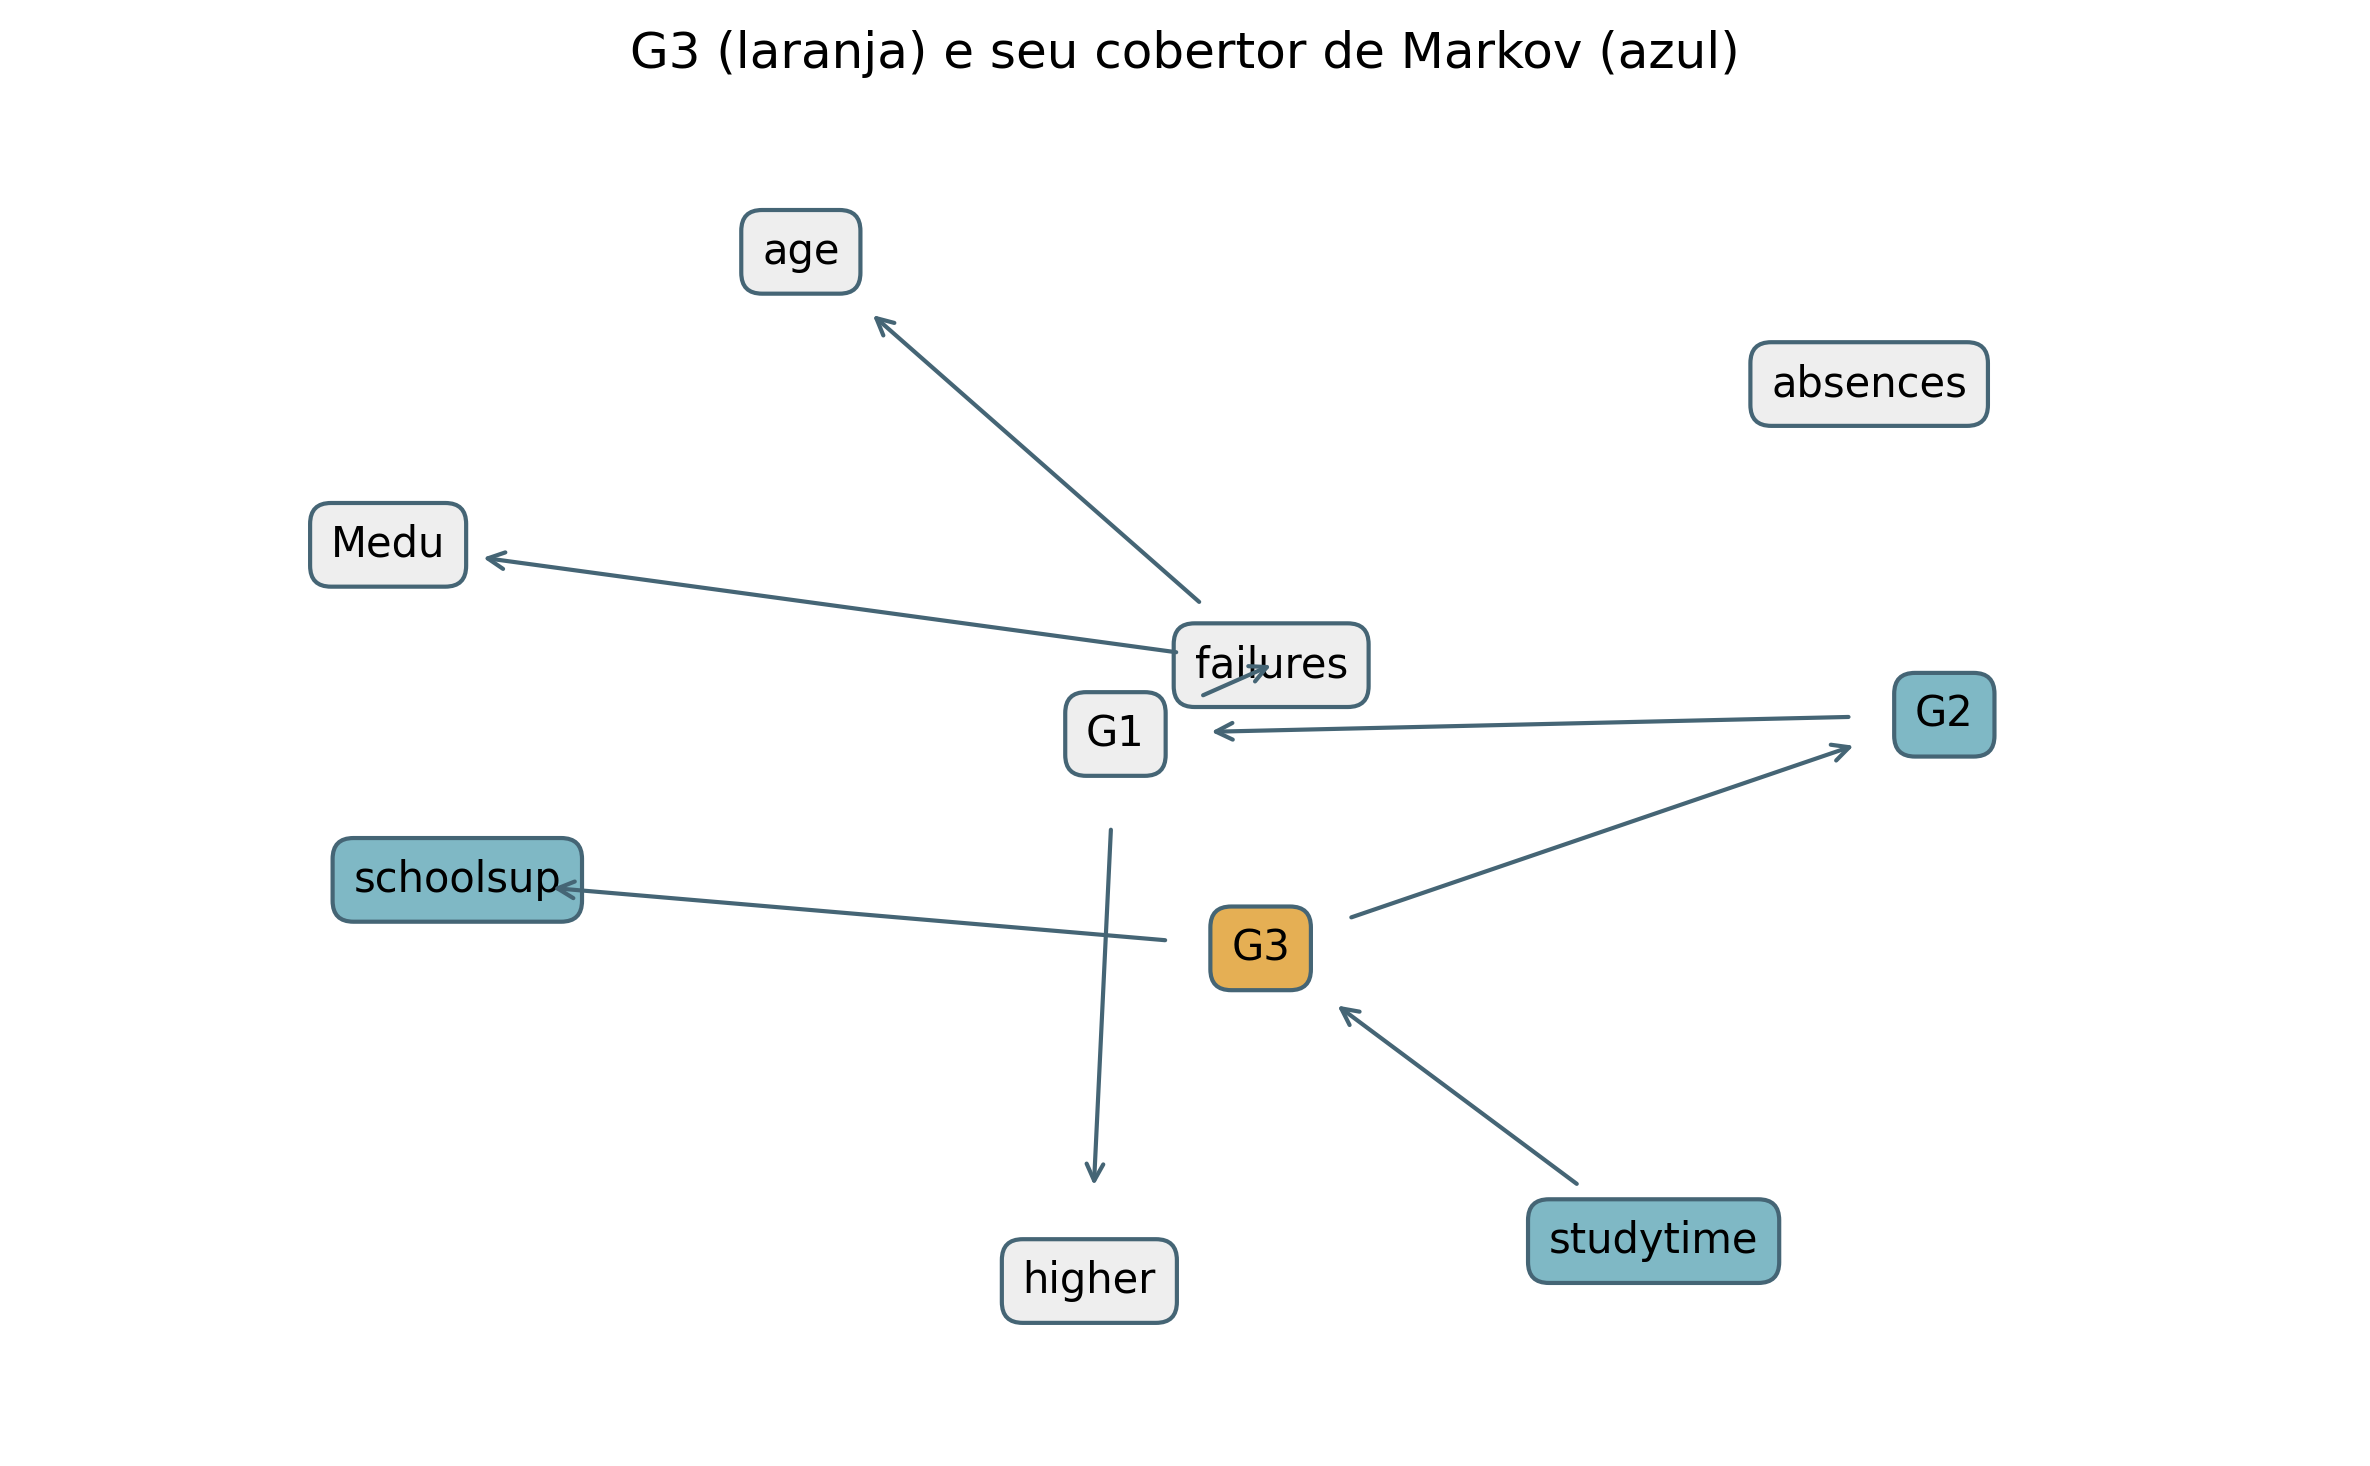

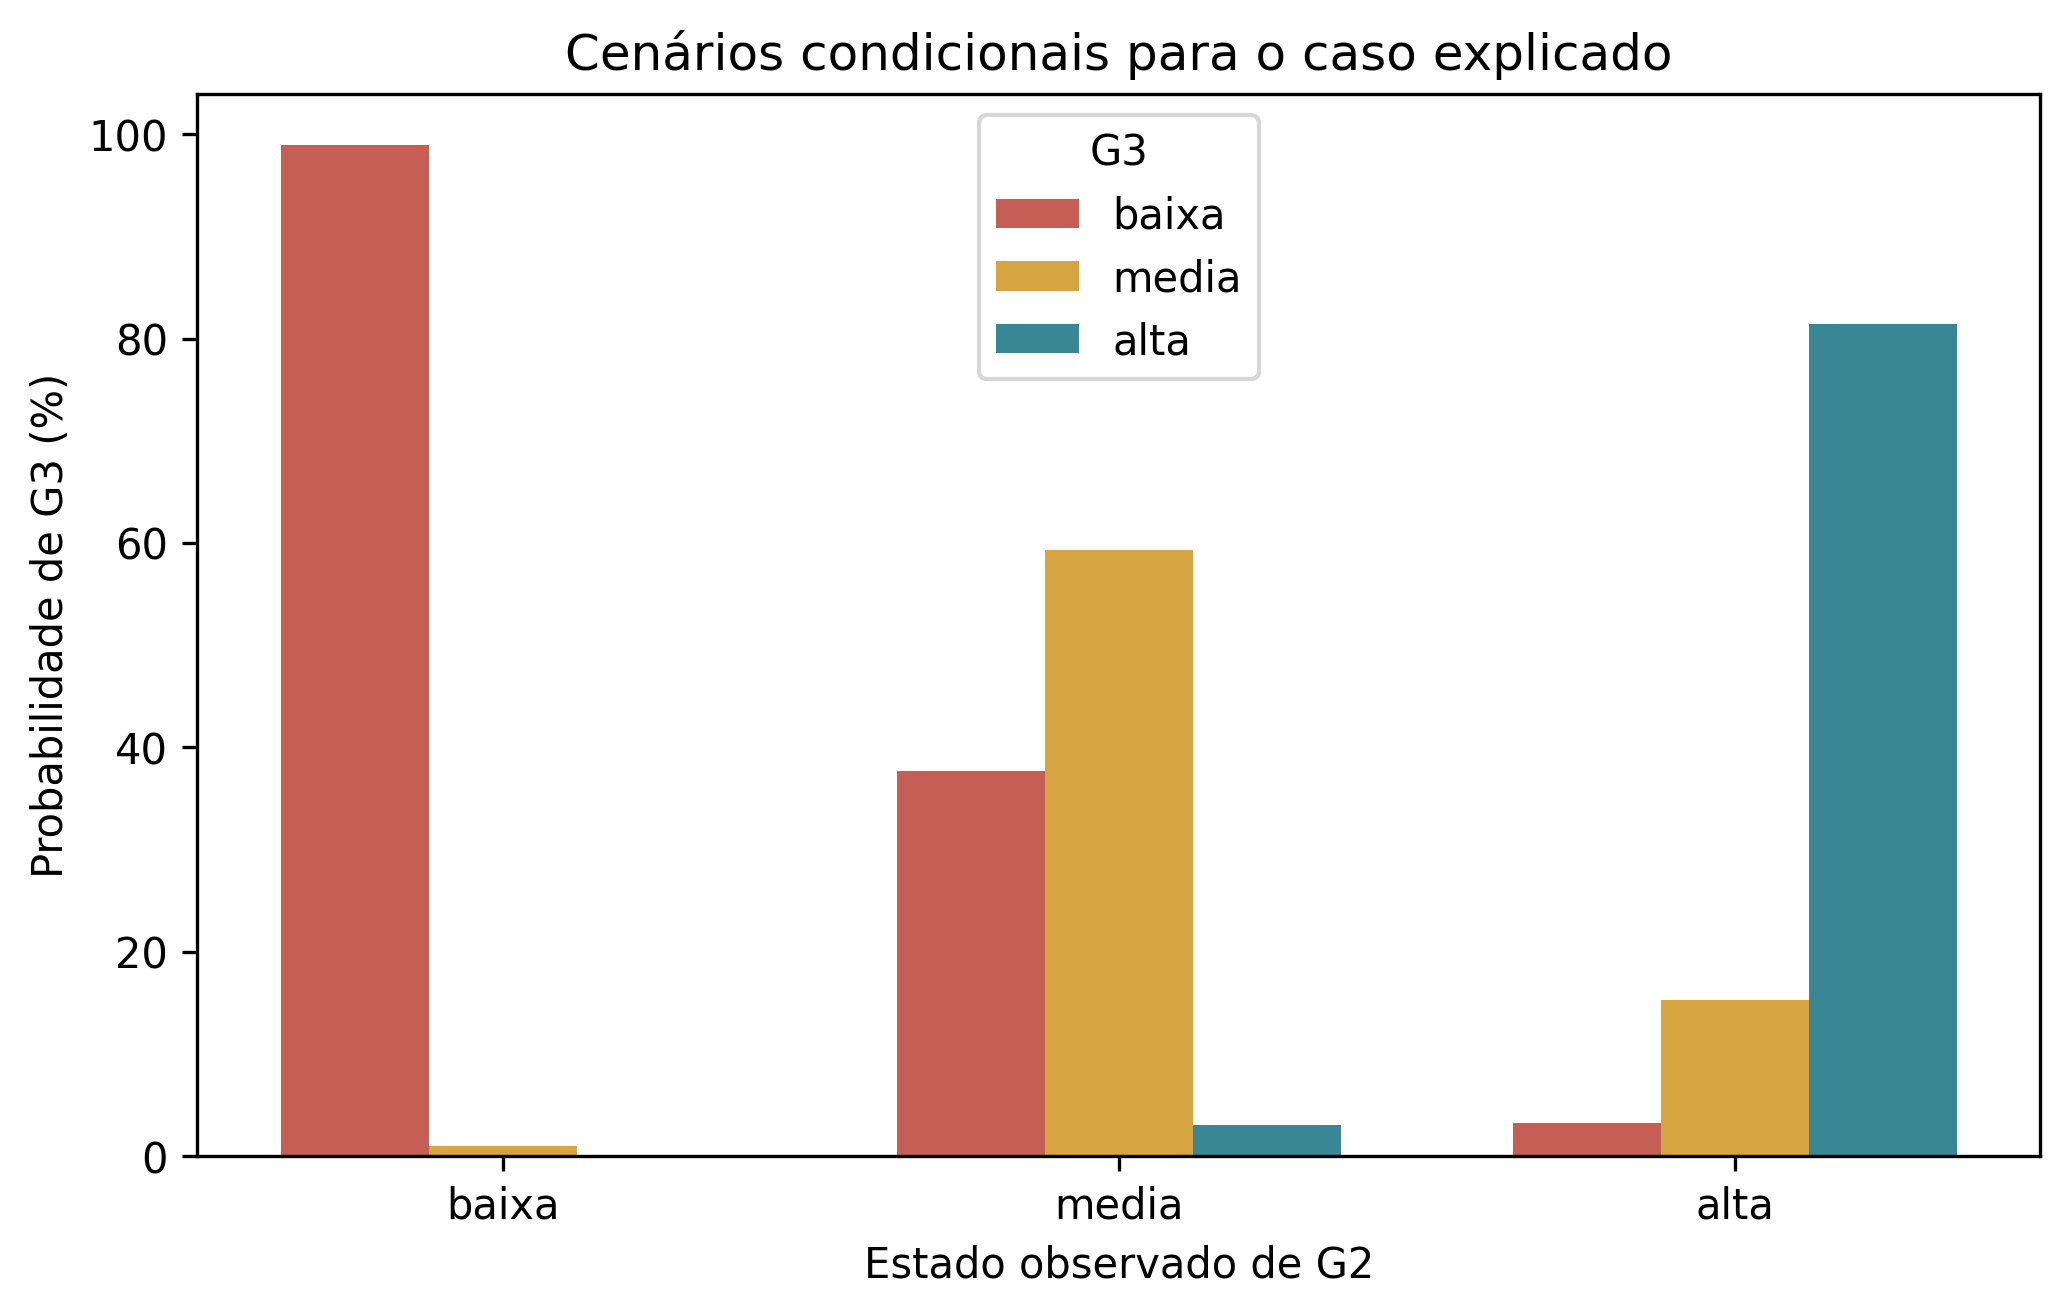

In [9]:
for arquivo in ['sensibilidade.png', 'figuras/cobertor_markov_g3.png', 'figuras/cenarios_alternativos_g2.png']:
    display(Image(filename=str(BASE / 'resultados' / arquivo)))

## Para interpretar

G3 baixa é uma faixa por quantis, não necessariamente reprovação. O uso de G2 corresponde ao acompanhamento após o segundo período. As alternativas de G2 são consultas condicionais, não intervenções causais. Consulte `README.md` para decisões e limitações e `ARQUIVOS_GERADOS.md` para localizar as saídas.

Fonte dos dados: https://doi.org/10.24432/C5TG7T. As referências de implementação estão no README.